# Projet final — Identifier l’utilisateur à partir des traces d’usage

Ce notebook repart des fichiers bruts `data/train.csv` et `data/test.csv`, contrôle leur structure, nettoie et représente les sessions, compare des modèles, évalue une solution sur des sessions gardées à part, analyse les erreurs puis génère une soumission Kaggle.

**Résultat exploratoire avant création de ce notebook :** sur un découpage stratifié externe 80/20, le modèle combinant un SVM TF-IDF (séquences d’événements) et un Random Forest (compteurs/contextes) a obtenu **96,65 % d’accuracy et 0,9607 de F1 macro**. Le mélange a été choisi uniquement sur une validation interne du train. Ces résultats seront recalculés dans le notebook. Ils ne sont ni une promesse de 99,4 %, ni un score Kaggle.

**Important :** `test.csv` n’a pas de colonne utilisateur. Il est impossible de calculer les métriques réelles sur les données Kaggle sans leurs labels. Toutes les métriques du notebook proviennent d’un jeu de validation interne extrait de `train.csv`.

## Plan méthodologique

1. Lire les CSV irréguliers sans en-tête : une ligne par session, longueur variable, label uniquement dans le train.
2. Contrôler les lignes, les champs vides, les utilisateurs, les navigateurs, les durées et les doublons.
3. Garder deux vues complémentaires des traces : séquences ordonnées exactes pour TF-IDF/SVM; compteurs d’actions, d’écrans, de configurations, de chaînes et de session pour Random Forest.
4. Isoler un jeu externe stratifié avant toute sélection du poids de combinaison; ajuster le poids et la température du mélange sur une validation interne seulement.
5. Comparer le SVM, le Random Forest, leur mélange et une baseline majoritaire; mesurer précision, rappel, F1 macro/pondéré et accuracy.
6. Après l’évaluation, réentraîner les modèles sur toutes les lignes étiquetées et sauvegarder `data/processed/final_submission.csv`.

Le SVM est retenu comme modèle séquentiel car les actions proches dans une session forment des motifs informatifs. Le Random Forest complète cette représentation avec des compteurs non ordonnés et des statistiques de session. Le modèle final est un mélange de leurs scores, choisi sur des données de validation distinctes.

## 1. Configuration et dépendances

In [4]:
from pathlib import Path
import csv
import hashlib
import re
import sys
import warnings
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC

# Configuration principale, pour pouvoir reproduire l'expérience.
SEED = 42
OUTER_VALIDATION_SEED = 31415
INNER_VALIDATION_SEED = 42
OUTER_VALIDATION_SIZE = 0.20
INNER_VALIDATION_SIZE = 0.20
TFIDF_NGRAM_RANGE = (1, 3)
TFIDF_MIN_DF = 2
SVM_C = 3.0
SVM_CLASS_WEIGHT = "balanced"
RF_TREES = 500
RF_MIN_SAMPLES_LEAF = 2
BLEND_TEMPERATURES = (0.1, 0.2, 0.35, 0.5)
BLEND_RF_WEIGHTS = (0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3)
N_JOBS = -1

warnings.filterwarnings("ignore", category=RuntimeWarning, module="sklearn")
sns.set_theme(style="whitegrid")
print("Python:", sys.executable, sys.version.split()[0])

Python: /Library/Developer/CommandLineTools/usr/bin/python3 3.9.6


## 2. Chargement et validation des fichiers bruts

On n’utilise pas `pandas.read_csv` pour parser les traces brutes : les lignes n’ont pas toutes le même nombre de champs. Le module `csv` respecte le nombre variable de tokens sans remplir artificiellement les sessions courtes.

In [5]:
def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "data" / "train.csv").is_file() and (candidate / "data" / "test.csv").is_file():
            return candidate
    raise FileNotFoundError("Placez/exécutez ce notebook dans le dépôt qui contient data/train.csv et data/test.csv.")

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
DATA_DIR = PROJECT_ROOT / "data"
TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"

TIME_RE = re.compile(r"^t\d+$")
SCREEN_RE = re.compile(r"\((.*?)\)")
CONFIG_RE = re.compile(r"<(.*?)>")
CHAIN_RE = re.compile(r"\$(.*?)\$")

def read_sessions(path: Path, labeled: bool) -> list[dict]:
    """Read a raw, ragged CSV and preserve original event order."""
    sessions = []
    prefix_size = 2 if labeled else 1
    with path.open(encoding="utf-8", newline="") as stream:
        for row_number, row in enumerate(csv.reader(stream), start=1):
            if len(row) < prefix_size:
                raise ValueError(f"{path.name}, ligne {row_number}: champs d'identité/navigateur manquants")
            row = [field.strip() for field in row]
            if any(field == "" for field in row):
                raise ValueError(f"{path.name}, ligne {row_number}: champ vide détecté")
            if labeled:
                user, browser, events = row[0], row[1], row[2:]
                if not re.fullmatch(r"[a-zA-Z]{3}", user):
                    raise ValueError(f"Identifiant utilisateur inattendu en ligne {row_number}: {user!r}")
            else:
                user, browser, events = None, row[0], row[1:]
            sessions.append({
                "session_id": row_number,
                "util": user,
                "navigateur": browser,
                "events": events,
            })
    return sessions

train_sessions = read_sessions(TRAIN_PATH, labeled=True)
test_sessions = read_sessions(TEST_PATH, labeled=False)
y = np.asarray([session["util"] for session in train_sessions], dtype=str)

sample_path = DATA_DIR / "sample_submission.csv"
sample_submission = pd.read_csv(sample_path)
if sample_submission.columns.tolist() != ["RowId", "prediction"]:
    raise ValueError("L'en-tête du sample_submission.csv n'est pas RowId,prediction")
if len(sample_submission) != len(test_sessions):
    raise ValueError("Le nombre de lignes du sample submission et du test diffère.")

print("Racine:", PROJECT_ROOT)
print(f"Train: {len(train_sessions):,} sessions | Test: {len(test_sessions):,} sessions")
print("Utilisateurs train:", len(set(y)))
print("Champs par session (train) min/max:", min(len(s["events"]) for s in train_sessions), max(len(s["events"]) for s in train_sessions))
print("Champs par session (test) min/max:", min(len(s["events"]) for s in test_sessions), max(len(s["events"]) for s in test_sessions))
print("En-tête submission:", sample_submission.columns.tolist())
display(pd.DataFrame([
    {"session_id": s["session_id"], "util": s["util"], "navigateur": s["navigateur"], "n_events": len(s["events"]), "aperçu": s["events"][:4]}
    for s in train_sessions[:5]
]))

Racine: /Users/macairm1/Desktop/3AECLM2/BE/ML & DS/BE_MachineLearning
Train: 3,279 sessions | Test: 324 sessions
Utilisateurs train: 247
Champs par session (train) min/max: 2 14468
Champs par session (test) min/max: 13 7725
En-tête submission: ['RowId', 'prediction']


,session_id,util,navigateur,n_events,aperçu
0,1,nuh,Firefox,3128,[Création d'un écran(infologic.core.accueil.Ac...
1,2,muz,Google Chrome,136,[Création d'un écran(infologic.core.gui.contro...
2,3,zrx,Microsoft Edge,766,[Affichage d'une dialogue(infologic.core.gui.c...
3,4,pou,Firefox,1199,[Création d'un écran(infologic.core.gui.contro...
4,5,ald,Google Chrome,233,[Affichage d'une dialogue(infologic.acti.modul...


## 3. Exploration et contrôles qualité

Les données contiennent 247 utilisateurs avec des effectifs inégaux. On vérifie la distribution des classes, des navigateurs, des longueurs de session, le vocabulaire des actions et les sessions brutes identiques portant éventuellement des labels différents. Les répétitions de `tNN` ne sont pas des actions et sont exclues de la séquence modèle.

Effectifs utilisateurs min/médiane/max: 4 12 75
Navigateurs train: {'Firefox': 1466, 'Google Chrome': 1339, 'Microsoft Edge': 451, 'Opera': 23}
Navigateurs test: {'Firefox': 147, 'Google Chrome': 133, 'Microsoft Edge': 42, 'Opera': 2}
Actions distinctes: 35 | événements identiques avec labels contradictoires: 0
Marqueurs tNN: valeurs en secondes suivant l'énoncé; ils sont exclus de la séquence d'actions.


,sessions
utilisateur,
skm,75
slq,71
cjr,46
flj,42
hjs,37
vfo,35
shh,34
nqg,34
fwf,33


,sessions,part
navigateur,,
Firefox,1466,0.447
Google Chrome,1339,0.408
Microsoft Edge,451,0.138
Opera,23,0.007


,occurrences
Exécution d'un bouton,510645
Saisie dans un champ,265633
Sélection d'un écran,206813
Fermeture d'une dialogue,171026
Affichage d'une dialogue,168928
Lancement d'une action générique,115283
Sélection d’un onglet,109209
Raccourci,82176
Création d'un écran,76930
Chainage,68194


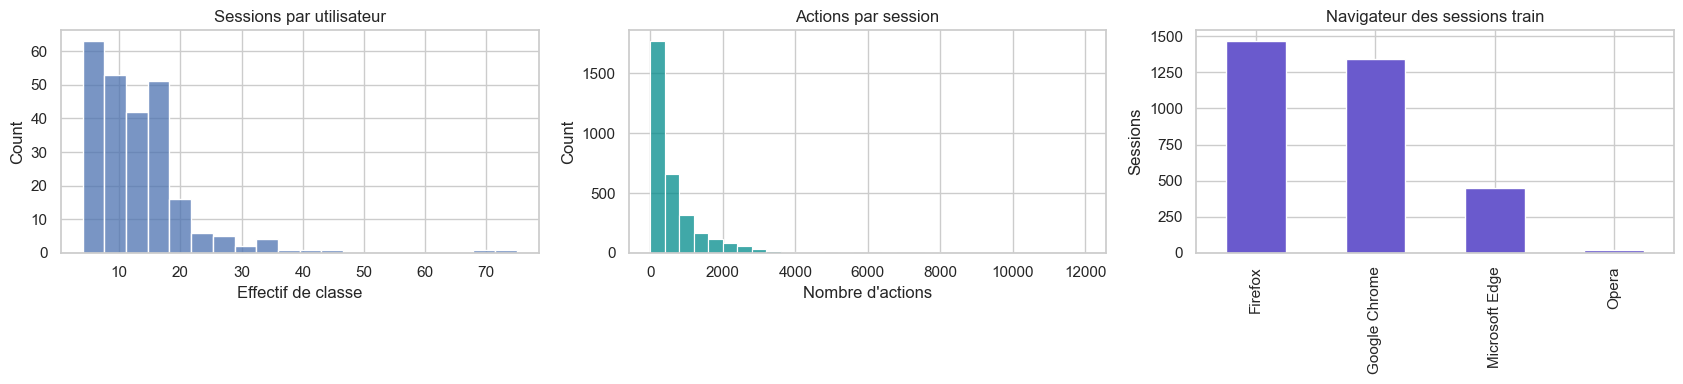

In [6]:
def action_name(event: str) -> str:
    cut_positions = [event.find(mark) for mark in ("(", "<", "$") if event.find(mark) > 0]
    action = event[:min(cut_positions)] if cut_positions else event
    return action[:-1] if action.endswith("1") else action

def session_summary(session: dict) -> dict:
    events = session["events"]
    time_values = [int(token[1:]) for token in events if TIME_RE.fullmatch(token)]
    actions = [action_name(token) for token in events if not TIME_RE.fullmatch(token)]
    screens = [m.group(1) for token in events for m in [SCREEN_RE.search(token)] if m]
    configs = [m.group(1) for token in events for m in [CONFIG_RE.search(token)] if m]
    chains = [m.group(1) for token in events for m in [CHAIN_RE.search(token)] if m]
    return {
        "session_id": session["session_id"],
        "util": session["util"],
        "navigateur": session["navigateur"],
        "n_tokens": len(events),
        "n_actions": len(actions),
        "n_time_markers": len(time_values),
        "max_time_seconds": max(time_values, default=0),
        "n_distinct_actions": len(set(actions)),
        "n_screens": len(screens),
        "n_distinct_screens": len(set(screens)),
        "n_configs": len(configs),
        "n_chains": len(chains),
    }

train_meta = pd.DataFrame([session_summary(s) for s in train_sessions])
test_meta = pd.DataFrame([session_summary(s) for s in test_sessions])
class_counts = train_meta["util"].value_counts()
browser_counts = train_meta["navigateur"].value_counts()
all_actions = Counter(action_name(token) for s in train_sessions for token in s["events"] if not TIME_RE.fullmatch(token))

def sequence_signature(session: dict) -> str:
    canonical = "\x1e".join([session["navigateur"], *[t for t in session["events"] if not TIME_RE.fullmatch(t)]])
    return hashlib.sha256(canonical.encode("utf-8")).hexdigest()

duplicate_labels = defaultdict(set)
for session in train_sessions:
    duplicate_labels[sequence_signature(session)].add(session["util"])
exact_duplicate_groups = [labels for labels in duplicate_labels.values() if len(labels) > 1]

print("Effectifs utilisateurs min/médiane/max:", int(class_counts.min()), int(class_counts.median()), int(class_counts.max()))
print("Navigateurs train:", browser_counts.to_dict())
print("Navigateurs test:", test_meta["navigateur"].value_counts().to_dict())
print("Actions distinctes:", len(all_actions), "| événements identiques avec labels contradictoires:", len(exact_duplicate_groups))
print("Marqueurs tNN: valeurs en secondes suivant l'énoncé; ils sont exclus de la séquence d'actions.")
display(class_counts.head(15).rename_axis("utilisateur").to_frame("sessions"))
display(pd.DataFrame({"sessions": browser_counts, "part": (browser_counts / len(train_meta)).round(3)}))
display(pd.Series(all_actions).sort_values(ascending=False).head(15).rename("occurrences").to_frame())

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(class_counts, bins=20, ax=axes[0])
axes[0].set(title="Sessions par utilisateur", xlabel="Effectif de classe")
sns.histplot(train_meta["n_actions"], bins=30, ax=axes[1], color="darkcyan")
axes[1].set(title="Actions par session", xlabel="Nombre d'actions")
browser_counts.plot(kind="bar", ax=axes[2], color="slateblue")
axes[2].set(title="Navigateur des sessions train", ylabel="Sessions", xlabel="")
plt.tight_layout()
plt.show()

## 4. Construire les deux représentations depuis les traces brutes

**Vue SVM — séquence TF-IDF.** Un token est un événement complet dans son ordre d’origine; les n-grammes représentent les événements consécutifs. On ajoute le navigateur comme token, et on écarte les repères `tNN` de la séquence car ils sont réguliers et le test préalable a montré qu’ils dégradaient le score.

**Vue Random Forest — caractéristiques interprétables.** Pour chaque session, compter les types d’action, événements complets et contextes extraits (`(...)`, `<...>`, `$...$`), avec des résumés numériques et le navigateur. Un `DictVectorizer` apprend l’encodage sur le sous-ensemble d’entraînement uniquement.

La cible `util` n’entre dans aucune des deux vues.

In [7]:
TOKEN_SEPARATOR = "\x1f"

def sequence_document(session: dict, include_time_markers: bool = False) -> str:
    tokens = [f"BROWSER={session['navigateur']}"]
    tokens.extend(
        token for token in session["events"]
        if include_time_markers or not TIME_RE.fullmatch(token)
    )
    return TOKEN_SEPARATOR.join(tokens)

def rf_features(session: dict) -> dict[str, float]:
    events = session["events"]
    counts = Counter()
    times = []
    actions = []
    screens = []
    configs = []
    chains = []
    modified = 0

    for token in events:
        if TIME_RE.fullmatch(token):
            times.append(int(token[1:]))
            continue
        action = action_name(token)
        actions.append(action)
        counts[f"action__{action}"] += 1
        counts[f"event__{token}"] += 1
        modified += token.endswith("1")
        for prefix, pattern, destination in (
            ("screen", SCREEN_RE, screens),
            ("config", CONFIG_RE, configs),
            ("chain", CHAIN_RE, chains),
        ):
            match = pattern.search(token)
            if match:
                value = match.group(1)
                destination.append(value)
                counts[f"{prefix}__{value}"] += 1

    counts.update({
        f"browser__{session['navigateur']}": 1,
        "summary__n_tokens": len(events),
        "summary__n_actions": len(actions),
        "summary__n_time_markers": len(times),
        "summary__max_time_seconds": max(times, default=0),
        "summary__n_distinct_actions": len(set(actions)),
        "summary__n_screens": len(screens),
        "summary__n_distinct_screens": len(set(screens)),
        "summary__n_configs": len(configs),
        "summary__n_distinct_configs": len(set(configs)),
        "summary__n_chains": len(chains),
        "summary__n_distinct_chains": len(set(chains)),
        "summary__n_modified_actions": modified,
    })
    return dict(counts)

train_documents = [sequence_document(s) for s in train_sessions]
test_documents = [sequence_document(s) for s in test_sessions]
train_rf_rows = [rf_features(s) for s in train_sessions]
test_rf_rows = [rf_features(s) for s in test_sessions]

print("SVM: document examples, tokens are separated with an internal delimiter:")
display(pd.DataFrame({"util": y[:3], "ordered_tokens": [s.split(TOKEN_SEPARATOR)[:8] for s in train_documents[:3]]}))
print("RF: number of distinct numeric/categorical keys in first rows:", [len(row) for row in train_rf_rows[:5]])
print("Unique action types:", len(all_actions))

SVM: document examples, tokens are separated with an internal delimiter:


,util,ordered_tokens
0,nuh,"[BROWSER=Firefox, Création d'un écran(infologi..."
1,muz,"[BROWSER=Google Chrome, Création d'un écran(in..."
2,zrx,"[BROWSER=Microsoft Edge, Affichage d'une dialo..."


RF: number of distinct numeric/categorical keys in first rows: [97, 56, 144, 103, 78]
Unique action types: 35


## 5. Validation imbriquée — séparation anti-fuite

Le split externe est mis de côté pour l’évaluation finale. Le poids du mélange et sa température sont choisis exclusivement sur le split interne du train externe. Aucun vocabulaire TF-IDF, encodage Random Forest, poids de mélange, ni autre prétraitement n’est ajusté avec les lignes externes d’évaluation.

La stratification est nécessaire pour garder des exemples de chaque utilisateur dans les ensembles. Les classes les plus rares ont quatre sessions seulement; leurs métriques par utilisateur sont nécessairement plus incertaines.

In [8]:
indices = np.arange(len(y))
dev_idx, outer_eval_idx = train_test_split(
    indices,
    test_size=OUTER_VALIDATION_SIZE,
    random_state=OUTER_VALIDATION_SEED,
    stratify=y,
)
inner_fit_idx, inner_val_idx = train_test_split(
    dev_idx,
    test_size=INNER_VALIDATION_SIZE,
    random_state=INNER_VALIDATION_SEED,
    stratify=y[dev_idx],
)

split_table = pd.DataFrame([
    {"split": "fit interne", "sessions": len(inner_fit_idx), "utilisateurs présents": len(set(y[inner_fit_idx]))},
    {"split": "validation de sélection", "sessions": len(inner_val_idx), "utilisateurs présents": len(set(y[inner_val_idx]))},
    {"split": "validation externe finale", "sessions": len(outer_eval_idx), "utilisateurs présents": len(set(y[outer_eval_idx]))},
])
display(split_table)
assert set(y[inner_fit_idx]) == set(y[dev_idx])
assert set(y[outer_eval_idx]).issubset(set(y[dev_idx]))
assert not (set(outer_eval_idx) & set(dev_idx))

,split,sessions,utilisateurs présents
0,fit interne,2098,247
1,validation de sélection,525,247
2,validation externe finale,656,247


## 6. Entraînement interne et réglage du mélange

Le SVM utilise TF-IDF par événement et n-grammes (1 à 3), avec `min_df=2`, `C=3` et poids de classes équilibrés. Le Random Forest utilise des événements/contextes comptés et des statistiques, avec 500 arbres, `max_features='sqrt'`, feuilles de taille minimale 2 et `balanced_subsample`.

Les scores SVM (marges) sont convertis en valeurs de confiance par softmax avec plusieurs températures. Ces valeurs sont fusionnées aux probabilités du Random Forest. La température et la part RF sont choisies par F1 macro sur la validation interne, puis verrouillées avant l’évaluation externe.

In [9]:
def build_tfidf() -> TfidfVectorizer:
    return TfidfVectorizer(
        tokenizer=lambda document: document.split(TOKEN_SEPARATOR),
        preprocessor=None,
        token_pattern=None,
        lowercase=False,
        ngram_range=TFIDF_NGRAM_RANGE,
        min_df=TFIDF_MIN_DF,
        sublinear_tf=True,
        dtype=np.float32,
    )

def build_svm() -> LinearSVC:
    return LinearSVC(C=SVM_C, class_weight=SVM_CLASS_WEIGHT, random_state=SEED, dual="auto")

def build_rf() -> RandomForestClassifier:
    return RandomForestClassifier(
        n_estimators=RF_TREES,
        max_features="sqrt",
        min_samples_leaf=RF_MIN_SAMPLES_LEAF,
        class_weight="balanced_subsample",
        random_state=SEED,
        n_jobs=N_JOBS,
    )

def fit_pair(fit_indices: np.ndarray, predict_indices: np.ndarray, seed: int):
    """Fit both representations only on fit_indices; return aligned scores."""
    vectorizer = build_tfidf()
    X_svm_fit = vectorizer.fit_transform([train_documents[i] for i in fit_indices])
    X_svm_pred = vectorizer.transform([train_documents[i] for i in predict_indices])
    svm = LinearSVC(C=SVM_C, class_weight=SVM_CLASS_WEIGHT, random_state=seed, dual="auto")
    svm.fit(X_svm_fit, y[fit_indices])
    svm_margins = svm.decision_function(X_svm_pred)

    dict_vectorizer = DictVectorizer(sparse=True, dtype=np.float32)
    X_rf_fit = dict_vectorizer.fit_transform([train_rf_rows[i] for i in fit_indices])
    X_rf_pred = dict_vectorizer.transform([train_rf_rows[i] for i in predict_indices])
    rf = build_rf().set_params(random_state=seed)
    rf.fit(X_rf_fit, y[fit_indices])
    rf_probabilities_raw = rf.predict_proba(X_rf_pred)

    svm_classes = svm.classes_
    rf_column = {label: column for column, label in enumerate(rf.classes_)}
    rf_probabilities = np.zeros((len(predict_indices), len(svm_classes)), dtype=np.float64)
    for column, label in enumerate(svm_classes):
        if label in rf_column:
            rf_probabilities[:, column] = rf_probabilities_raw[:, rf_column[label]]
    return {
        "classes": svm_classes,
        "svm_margins": svm_margins,
        "rf_probabilities": rf_probabilities,
        "svm": svm,
        "rf": rf,
        "tfidf": vectorizer,
        "dict_vectorizer": dict_vectorizer,
    }

def svm_probabilities(margins: np.ndarray, temperature: float) -> np.ndarray:
    scaled = margins / temperature
    scaled = scaled - scaled.max(axis=1, keepdims=True)
    exp_scores = np.exp(scaled)
    return exp_scores / exp_scores.sum(axis=1, keepdims=True)

def blended_prediction(model_outputs: dict, temperature: float, rf_weight: float) -> np.ndarray:
    svm_probs = svm_probabilities(model_outputs["svm_margins"], temperature)
    combined = (1.0 - rf_weight) * svm_probs + rf_weight * model_outputs["rf_probabilities"]
    return model_outputs["classes"][combined.argmax(axis=1)]

def metrics_row(name: str, truth: np.ndarray, prediction: np.ndarray) -> dict:
    p_macro, r_macro, f_macro, _ = precision_recall_fscore_support(truth, prediction, average="macro", zero_division=0)
    p_weighted, r_weighted, f_weighted, _ = precision_recall_fscore_support(truth, prediction, average="weighted", zero_division=0)
    return {
        "Modèle": name,
        "Accuracy": accuracy_score(truth, prediction),
        "Précision macro": p_macro,
        "Rappel macro": r_macro,
        "F1 macro": f_macro,
        "Précision pondérée": p_weighted,
        "Rappel pondéré": r_weighted,
        "F1 pondéré": f_weighted,
    }

inner_models = fit_pair(inner_fit_idx, inner_val_idx, SEED)
inner_truth = y[inner_val_idx]
inner_svm_pred = inner_models["classes"][inner_models["svm_margins"].argmax(axis=1)]
inner_rf_pred = inner_models["classes"][inner_models["rf_probabilities"].argmax(axis=1)]
inner_base_metrics = pd.DataFrame([
    metrics_row("SVM séquentiel", inner_truth, inner_svm_pred),
    metrics_row("Random Forest", inner_truth, inner_rf_pred),
])
display(inner_base_metrics.round(4))

blend_trials = []
for temperature in BLEND_TEMPERATURES:
    for rf_weight in BLEND_RF_WEIGHTS:
        prediction = blended_prediction(inner_models, temperature, rf_weight)
        row = metrics_row("mélange", inner_truth, prediction)
        row.update({"température": temperature, "poids_RF": rf_weight})
        blend_trials.append(row)
blend_trials_df = pd.DataFrame(blend_trials).sort_values(["F1 macro", "Accuracy"], ascending=False)
display(blend_trials_df.head(10).round(4))
best_blend = blend_trials_df.iloc[0]
BEST_TEMPERATURE = float(best_blend["température"])
BEST_RF_WEIGHT = float(best_blend["poids_RF"])
print(f"Paramètres du mélange choisis sur validation interne uniquement: température={BEST_TEMPERATURE}, poids RF={BEST_RF_WEIGHT}")

,Modèle,Accuracy,Précision macro,Rappel macro,F1 macro,Précision pondérée,Rappel pondéré,F1 pondéré
0,SVM séquentiel,0.9390,0.9305,0.9348,0.9265,0.9381,0.9390,0.9319
1,Random Forest,0.8933,0.8659,0.8718,0.8582,0.8884,0.8933,0.8792


,Modèle,Accuracy,Précision macro,Rappel macro,F1 macro,Précision pondérée,Rappel pondéré,F1 pondéré,température,poids_RF
11,mélange,0.9467,0.9396,0.9416,0.9363,0.9425,0.9467,0.9392,0.20,0.20
22,mélange,0.9467,0.9344,0.9406,0.9342,0.9394,0.9467,0.9392,0.50,0.05
17,mélange,0.9467,0.9355,0.9402,0.9342,0.9413,0.9467,0.9396,0.35,0.15
10,mélange,0.9448,0.9347,0.9396,0.9326,0.9390,0.9448,0.9364,0.20,0.15
15,mélange,0.9448,0.9347,0.9396,0.9326,0.9390,0.9448,0.9364,0.35,0.05
23,mélange,0.9448,0.9318,0.9362,0.9306,0.9373,0.9448,0.9366,0.50,0.10
24,mélange,0.9429,0.9340,0.9358,0.9305,0.9382,0.9429,0.9353,0.50,0.15
12,mélange,0.9429,0.9327,0.9372,0.9305,0.9374,0.9429,0.9351,0.20,0.25
5,mélange,0.9429,0.9330,0.9382,0.9304,0.9393,0.9429,0.9353,0.10,0.25
6,mélange,0.9429,0.9330,0.9382,0.9304,0.9393,0.9429,0.9353,0.10,0.30


Paramètres du mélange choisis sur validation interne uniquement: température=0.2, poids RF=0.2


## 7. Évaluation externe verrouillée

Les réglages de mélange sont maintenant fixés. Les deux modèles sont entraînés sur le développement complet (80 % du train); aucune décision de modèle n’est prise à partir des résultats externes ci-dessous. On compare baseline majoritaire, SVM, Random Forest et le mélange.

In [10]:
outer_models = fit_pair(dev_idx, outer_eval_idx, SEED + 1)
outer_truth = y[outer_eval_idx]
outer_svm_pred = outer_models["classes"][outer_models["svm_margins"].argmax(axis=1)]
outer_rf_pred = outer_models["classes"][outer_models["rf_probabilities"].argmax(axis=1)]
outer_blend_pred = blended_prediction(outer_models, BEST_TEMPERATURE, BEST_RF_WEIGHT)
majority_label = Counter(y[dev_idx]).most_common(1)[0][0]
majority_pred = np.repeat(majority_label, len(outer_eval_idx))

outer_metrics = pd.DataFrame([
    metrics_row("Baseline — classe majoritaire", outer_truth, majority_pred),
    metrics_row("SVM TF-IDF séquentiel", outer_truth, outer_svm_pred),
    metrics_row("Random Forest sur compteurs", outer_truth, outer_rf_pred),
    metrics_row("Mélange SVM + Random Forest", outer_truth, outer_blend_pred),
]).sort_values("F1 macro", ascending=False).reset_index(drop=True)
display(outer_metrics.round(4))
print("Taille de l'évaluation externe:", len(outer_eval_idx), "sessions")
print("Les métriques sont calculées sur validation interne, non sur le test Kaggle.")

outer_train_svm_pred = outer_models["svm"].predict(outer_models["tfidf"].transform([train_documents[i] for i in dev_idx]))
outer_train_rf_pred = outer_models["rf"].predict(outer_models["dict_vectorizer"].transform([train_rf_rows[i] for i in dev_idx]))
generalization_gap = pd.DataFrame([
    metrics_row("SVM — train de fit", y[dev_idx], outer_train_svm_pred),
    metrics_row("SVM — validation externe", outer_truth, outer_svm_pred),
    metrics_row("RF — train de fit", y[dev_idx], outer_train_rf_pred),
    metrics_row("RF — validation externe", outer_truth, outer_rf_pred),
])
print("Comparaison train / validation pour détecter la mémorisation:")
display(generalization_gap[["Modèle", "Accuracy", "F1 macro", "F1 pondéré"]].round(4))

,Modèle,Accuracy,Précision macro,Rappel macro,F1 macro,Précision pondérée,Rappel pondéré,F1 pondéré
0,Mélange SVM + Random Forest,0.9665,0.9651,0.9616,0.9600,0.9646,0.9665,0.9618
1,SVM TF-IDF séquentiel,0.9604,0.9584,0.9583,0.9547,0.9595,0.9604,0.9559
2,Random Forest sur compteurs,0.8887,0.8631,0.8724,0.8555,0.8849,0.8887,0.8725
3,Baseline — classe majoritaire,0.0229,0.0001,0.0040,0.0002,0.0005,0.0229,0.0010


Taille de l'évaluation externe: 656 sessions
Les métriques sont calculées sur validation interne, non sur le test Kaggle.
Comparaison train / validation pour détecter la mémorisation:


,Modèle,Accuracy,F1 macro,F1 pondéré
0,SVM — train de fit,1.0000,1.0000,1.0000
1,SVM — validation externe,0.9604,0.9547,0.9559
2,RF — train de fit,0.9981,0.9989,0.9981
3,RF — validation externe,0.8887,0.8555,0.8725


## 8. Analyse des erreurs et variables Random Forest

Le F1 macro est la moyenne par utilisateur et rend visibles les classes rares. Les scores par classe ayant quatre sessions sont toutefois très sensibles au split. L’importance Random Forest est un indicateur interne aux arbres, non une relation causale.

15 classes les moins représentées dans l'évaluation externe:


,precision,recall,f1-score,support
utilisateur,,,,
azn,0.0,0.0,0.0,1.0
cuw,0.0,0.0,0.0,1.0
jew,0.0,0.0,0.0,1.0
ufc,0.0,0.0,0.0,1.0
urs,0.0,0.0,0.0,1.0
bez,1.0,1.0,1.0,1.0
cka,1.0,1.0,1.0,1.0
ckl,1.0,1.0,1.0,1.0
crn,1.0,1.0,1.0,1.0


Erreurs du mélange: 22 / 656 (3.4%)


,session_id,utilisateur_reel,utilisateur_predit,n_actions,navigateur
0,299,bos,czi,128,Firefox
31,2613,slq,skm,51,Google Chrome
69,1826,skm,slq,203,Google Chrome
110,619,ald,fuy,65,Google Chrome
148,298,azn,wht,87,Google Chrome
162,290,kks,tdk,35,Firefox
208,3183,oqa,vfo,335,Google Chrome
224,925,yvq,muz,130,Google Chrome
226,1306,guh,sps,122,Google Chrome
227,2829,hzx,zok,77,Microsoft Edge


,caractéristique,importance_Gini
8,action__Clic sur une grille d'historique de re...,0.007316
1594,event__Clic sur une grille d'historique de rec...,0.006518
35,browser__Firefox,0.006461
4205,event__Retour sur un écran,0.006337
27,action__Raccourci,0.006306
36,browser__Google Chrome,0.006093
363,event__Affichage d'un toast,0.006073
2244,event__Double-clic,0.006046
3840,event__Raccourci,0.006023
21,action__Filtrage / Tri,0.005995


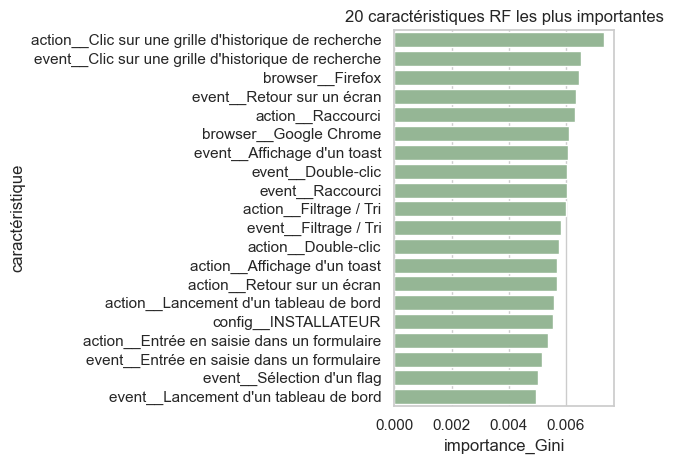

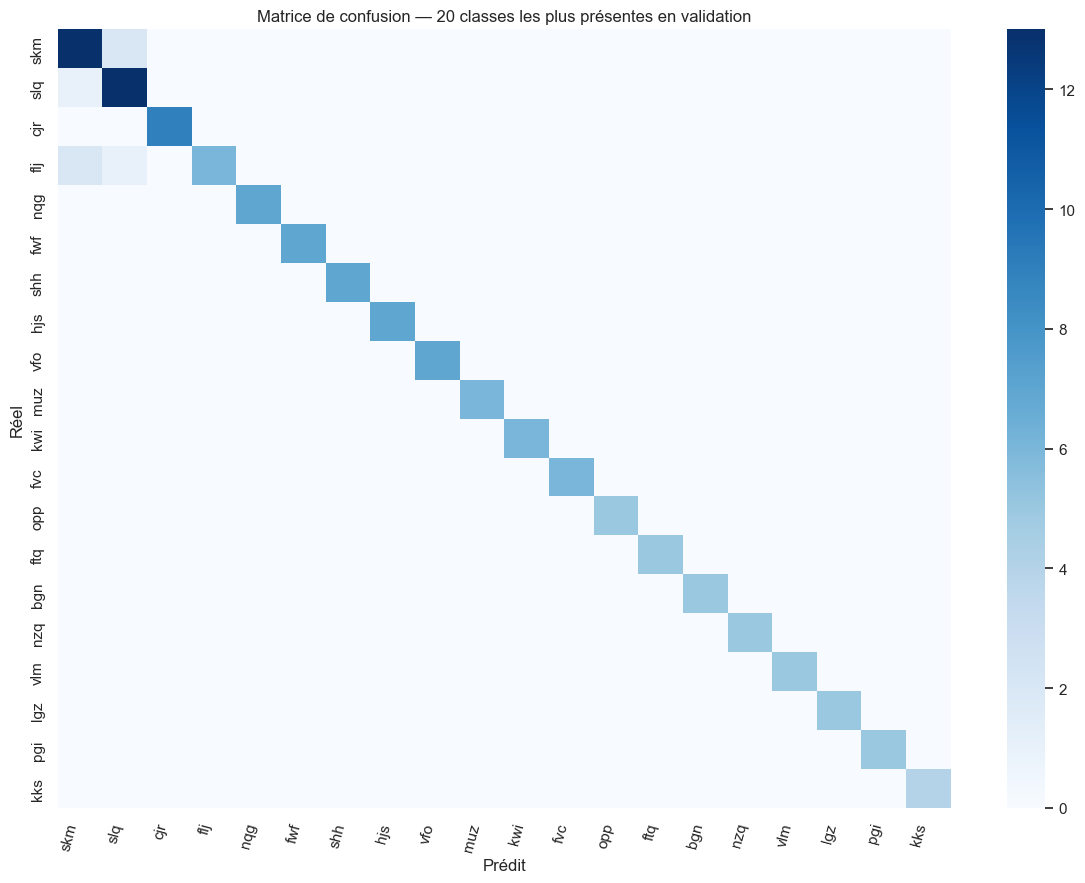

In [11]:
per_user = pd.DataFrame(classification_report(
    outer_truth,
    outer_blend_pred,
    labels=outer_models["classes"],
    output_dict=True,
    zero_division=0,
)).T
per_user = per_user.loc[per_user.index.isin(outer_models["classes"].astype(str))].copy()
per_user.index.name = "utilisateur"
per_user = per_user.sort_values(["support", "f1-score"], ascending=[True, True])
print("15 classes les moins représentées dans l'évaluation externe:")
display(per_user.head(15).round(3))

errors = pd.DataFrame({
    "session_id": [train_sessions[i]["session_id"] for i in outer_eval_idx],
    "utilisateur_reel": outer_truth,
    "utilisateur_predit": outer_blend_pred,
    "n_actions": [train_meta.iloc[i]["n_actions"] for i in outer_eval_idx],
    "navigateur": [train_sessions[i]["navigateur"] for i in outer_eval_idx],
})
errors = errors[errors["utilisateur_reel"] != errors["utilisateur_predit"]]
print(f"Erreurs du mélange: {len(errors)} / {len(outer_eval_idx)} ({len(errors)/len(outer_eval_idx):.1%})")
display(errors.head(20))

rf_vectorizer_outer = outer_models["dict_vectorizer"]
rf_importance = pd.DataFrame({
    "caractéristique": rf_vectorizer_outer.get_feature_names_out(),
    "importance_Gini": outer_models["rf"].feature_importances_,
}).sort_values("importance_Gini", ascending=False)
display(rf_importance.head(25))
sns.barplot(data=rf_importance.head(20), x="importance_Gini", y="caractéristique", color="darkseagreen")
plt.title("20 caractéristiques RF les plus importantes")
plt.tight_layout()
plt.show()

top_eval_classes = pd.Series(outer_truth).value_counts().head(20).index.to_list()
cm = confusion_matrix(outer_truth, outer_blend_pred, labels=top_eval_classes)
plt.figure(figsize=(12, 9))
sns.heatmap(cm, cmap="Blues", xticklabels=top_eval_classes, yticklabels=top_eval_classes)
plt.title("Matrice de confusion — 20 classes les plus présentes en validation")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

## 9. Réentraînement sur tout le train et prédiction Kaggle

Après l’évaluation, les modèles sont réentraînés sur toutes les sessions étiquetées. Le vocabulaire TF-IDF et le DictVectorizer sont refaits sur le train complet. Les prédictions test sont converties dans les identifiants utilisateur d’origine et sauvegardées dans l’ordre du fichier test.

In [12]:
final_tfidf = build_tfidf()
X_train_seq = final_tfidf.fit_transform(train_documents)
X_test_seq = final_tfidf.transform(test_documents)
final_svm = build_svm()
final_svm.fit(X_train_seq, y)
test_svm_margins = final_svm.decision_function(X_test_seq)

final_dict_vectorizer = DictVectorizer(sparse=True, dtype=np.float32)
X_train_counts = final_dict_vectorizer.fit_transform(train_rf_rows)
X_test_counts = final_dict_vectorizer.transform(test_rf_rows)
final_rf = build_rf()
final_rf.fit(X_train_counts, y)
test_rf_raw = final_rf.predict_proba(X_test_counts)

test_rf_probabilities = np.zeros((len(test_sessions), len(final_svm.classes_)), dtype=np.float64)
rf_label_to_column = {label: column for column, label in enumerate(final_rf.classes_)}
for column, label in enumerate(final_svm.classes_):
    test_rf_probabilities[:, column] = test_rf_raw[:, rf_label_to_column[label]]
final_outputs = {
    "classes": final_svm.classes_,
    "svm_margins": test_svm_margins,
    "rf_probabilities": test_rf_probabilities,
}
test_predictions = blended_prediction(final_outputs, BEST_TEMPERATURE, BEST_RF_WEIGHT)

submission = pd.DataFrame({
    "RowId": np.arange(1, len(test_predictions) + 1),
    "prediction": test_predictions,
})
submission_path = DATA_DIR / "processed" / "final_submission.csv"
submission_path.parent.mkdir(parents=True, exist_ok=True)
submission.to_csv(submission_path, index=False)

assert submission.columns.tolist() == ["RowId", "prediction"]
assert len(submission) == len(test_sessions) == len(sample_submission)
assert submission["RowId"].tolist() == sample_submission["RowId"].tolist()
assert set(submission["prediction"]).issubset(set(y))
print("Vocabulaire TF-IDF:", X_train_seq.shape[1], "| variables RF:", X_train_counts.shape[1])
print("Predictions:", len(submission), "| utilisateurs prédits:", submission["prediction"].nunique())
print("Fichier prêt pour Kaggle:", submission_path)
display(submission.head(10))
display(submission["prediction"].value_counts().head(15).rename("prédictions").to_frame())
print("Aucun score test n'est calculé : les labels utilisateurs du test ne sont pas fournis.")

Vocabulaire TF-IDF: 143357 | variables RF: 7851
Predictions: 324 | utilisateurs prédits: 221
Fichier prêt pour Kaggle: /Users/macairm1/Desktop/3AECLM2/BE/ML & DS/BE_MachineLearning/data/processed/final_submission.csv


,RowId,prediction
0,1,hzx
1,2,prb
2,3,jmq
3,4,psg
4,5,cvw
5,6,ald
6,7,nuh
7,8,lgz
8,9,nfh
9,10,pgu


,prédictions
prediction,
skm,7
slq,7
nqg,5
hjs,4
flj,4
cjr,4
vek,3
nzq,3
bgn,3


Aucun score test n'est calculé : les labels utilisateurs du test ne sont pas fournis.


## 10. Bilan, limites et pistes d’amélioration

- Les traces complètes en ordre apportent plus d’information que les seuls compteurs. Le meilleur modèle testé combine n-grammes d’événements avec TF-IDF/SVM et agrégats avec Random Forest.
- La validation externe est stratifiée et séparée du choix de poids du mélange. Les valeurs doivent être lues comme une estimation sur des sessions tirées de la même population, pas comme une garantie de score Kaggle.
- Un résultat de **99,4 %** ne peut pas être promis à partir du train seul. Une part des utilisateurs n’a que quatre sessions; la couverture et la variabilité des profils limitent les décisions certaines.
- Le fichier test ne contient pas la vérité terrain. Il n’existe donc pas de précision, rappel, F1 ou accuracy calculable sur le test local.
- Pour chercher à dépasser le résultat actuel sans surajuster une validation, les prochaines expériences recommandées sont une validation croisée imbriquée plus large, l’ajout de représentation de séquences plus fine, puis la comparaison sur le score officiel Kaggle. Ne choisir aucun modèle d’après le leaderboard seul sans garder une validation locale fixe.

Le tableau `outer_metrics` donne les mesures principales à rapporter; `submission` et le fichier CSV sont les prédictions à soumettre.